<a href="https://colab.research.google.com/github/A01178685/clase_lol_10/blob/main/Presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mexico’s Human Capital Index Comparison

# Mexico’s Human Capital Index Comparison

[Initial setup](#scrollTo=vseoY8IkIjKN)

[RQ1: How did Mexico’s HCI change from 2010 to 2020?](#scrollTo=HCIRQ1_2026)
   - Area plot

[RQ2: How did Mexico’s HCI change compare with the region and world?](#scrollTo=HCIRQ2_2026)
   - Horizontal bar plot

[RQ3: How did Mexico’s HCI level compare with the region and world in 2020?](#scrollTo=UR1cwwIHIPif&line)
   - Horizontal bar plot

[RQ4: Was Mexico’s HCI different for females and males in 2020?](#scrollTo=fDZtHk_gLlaZ&line)
   - Bar plot

[RQ5: How did the schooling indicators compare in Mexico in 2020?](#scrollTo=efS4ptxXMGu-&line)
   - Horizontal bar plot

[RQ6: How did learning-adjusted years of school change in Mexico?](#scrollTo=VSC1s08qMZke&line)
   - Area plot

[RQ7: How did Mexico’s adult survival rate compare in 2020?](#scrollTo=-pj7K-XdMw5r&line)
   - Horizontal bar plot

[RQ8: How did Mexico’s HCI compare with selected countries in 2020?](#scrollTo=JBWLoaRqNKDk&line)
   - Horizontal bar plot

[Final Conclusions](#scrollTo=Ykq3WWSelT2G&line)

## 1. initial setup



In [21]:
file_path = 'WB_HCI.csv'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv(file_path)
df.head()

,STRUCTURE,STRUCTURE_ID,ACTION,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,SEX,...,TIME_PERIOD,OBS_VALUE,DATABASE_ID,DATABASE_ID_LABEL,UNIT_MULT,UNIT_MULT_LABEL,UNIT_TYPE,UNIT_TYPE_LABEL,TIME_FORMAT,TIME_FORMAT_LABEL
0,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2010,0.840845,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
1,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2018,0.846043,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
2,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,WLD,World,WB_HCI_ASR,Adult Survival Rate,_T,...,2020,0.848294,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
3,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,EAS,East Asia & Pacific,WB_HCI_ASR,Adult Survival Rate,_T,...,2010,0.900628,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY
4,datastructure,WB.DATA360:DS_DATA360(1.2),I,A,Annual,EAS,East Asia & Pacific,WB_HCI_ASR,Adult Survival Rate,_T,...,2018,0.861863,WB_HCI,Human Capital Index (HCI),0,Units,RATIO,Ratio,602,CCYY


## Description of the dataset



WB_HCI.csv contains 15,039 rows and 33 columns of World Bank human capital data for 186 geographic areas. Each row records one indicator for an area, year, and sex category. The years used here are 2010, 2018, and 2020. World and Latin America & Caribbean are aggregate areas, while Mexico and the other named countries are individual countries.

Variables:

- REF_AREA_LABEL — categorical: Country or aggregate area, such as Mexico, Chile, or World.

- TIME_PERIOD — numerical, discrete year: The observation year (2010, 2018, or 2020).

- SEX_LABEL — categorical: Total, Female, or Male. Most questions use Total; RQ4 compares females and males.

- INDICATOR — categorical: Code for the selected measure: WB_HCI_HCI (Human Capital Index), WB_HCI_EYRS (expected years of school), WB_HCI_LAYS (learning-adjusted years of school), or WB_HCI_ASR (adult survival rate).

- INDICATOR_LABEL — categorical text: Full name of a measure, used to label the schooling graph.

- OBS_VALUE — numerical: Value of the selected measure. HCI is a score from 0 to 1; schooling is measured in years; adult survival is a proportion from 0 to 1.

HCI stands for Human Capital Index. It is a score related to expected health and education outcomes; a higher score means greater potential human capital. The graphs describe the recorded values and do not establish why they changed.

Purpose: First examine Mexico's HCI over time and compare it with the regional and World entries. Then explore differences by sex, schooling, adult survival, and selected countries.

Purpose: Examine Mexico’s HCI in 2010, 2018, and 2020, then compare its change with Latin America and the Caribbean and the World.

In [22]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'ACTION', 'FREQ', 'FREQ_LABEL', 'REF_AREA',
       'REF_AREA_LABEL', 'INDICATOR', 'INDICATOR_LABEL', 'SEX', 'SEX_LABEL',
       'AGE', 'AGE_LABEL', 'URBANISATION', 'URBANISATION_LABEL',
       'UNIT_MEASURE', 'UNIT_MEASURE_LABEL', 'COMP_BREAKDOWN_1',
       'COMP_BREAKDOWN_1_LABEL', 'COMP_BREAKDOWN_2', 'COMP_BREAKDOWN_2_LABEL',
       'COMP_BREAKDOWN_3', 'COMP_BREAKDOWN_3_LABEL', 'TIME_PERIOD',
       'OBS_VALUE', 'DATABASE_ID', 'DATABASE_ID_LABEL', 'UNIT_MULT',
       'UNIT_MULT_LABEL', 'UNIT_TYPE', 'UNIT_TYPE_LABEL', 'TIME_FORMAT',
       'TIME_FORMAT_LABEL'],
      dtype='object')

##Eight-study analytical roadmap
| Study | Research question | Study / figure | Main insight |
|---|---|---|---|
| 1 | How did Mexico’s HCI change? | Three observations; area plot | HCI increased by 0.024 points from 2010 to 2020. |
| 2 | How did that change compare with aggregates? | 2010–2020 differences; horizontal bars | Mexico gained 0.024; the region gained 0.010; World fell 0.030. |
| 3 | Did female and male HCI differ? | Mexico’s 2020 sex categories; bars | Female HCI was 0.627 and male HCI was 0.600. |
| 4 | How did the schooling measures compare? | Mexico’s 2020 EYRS and LAYS; horizontal bars | Expected schooling exceeded learning-adjusted schooling by 4.000 years. |
| 5 | How did LAYS change over time? | Mexico’s three years; area plot | LAYS increased by 0.320 years from 2010 to 2020. |
| 6 | How did adult survival compare? | 2020 Mexico, region, and World; horizontal bars | Mexico was near the region and above the World entry. |
| 7 | How did Mexico compare with selected countries? | Four 2020 HCI scores; horizontal bars | Mexico ranked second among the four selected countries. |
| 8 | How are schooling and survival associated with HCI? | Two predictor regression; observed/fitted scatterplot | R² is 0.986; fitted Mexico HCI is 0.614 versus observed 0.613. |

## RQ1: How did Mexico’s HCI change from 2010 to 2020?
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

**Study:** Select Mexico’s three available HCI scores, calculate the change and average change per year for each observed interval, and show an **area plot**. The interval averages account for 2010–2018 spanning eight years and 2018–2020 spanning two years.

TIME_PERIOD
2010    0.589119
2018    0.611657
2020    0.612950
Name: OBS_VALUE, dtype: float64
Increase, 2010–2020 (HCI points): 0.023831069469451904


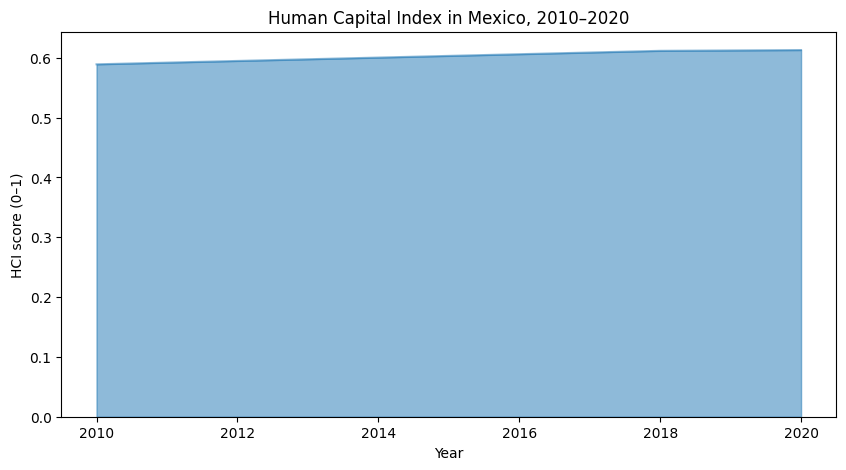

In [23]:
hci = df[df['INDICATOR'] == 'WB_HCI_HCI']
hci = hci[hci['SEX_LABEL'] == 'Total']

mexico = hci[hci['REF_AREA_LABEL'] == 'Mexico'].sort_values(['TIME_PERIOD']).set_index('TIME_PERIOD')['OBS_VALUE']
print(mexico)

aumento = mexico.loc[2020] - mexico.loc[2010]
print('Increase, 2010–2020 (HCI points):', aumento)

mexico.plot(kind='area', stacked=False, alpha=0.5, figsize=(10, 5))
plt.title('Human Capital Index in Mexico, 2010–2020')
plt.xlabel('Year')
plt.ylabel('HCI score (0–1)')
plt.show()

### Insight
Mexico’s HCI rose from 0.589 in 2010 to 0.613 in 2020, about 0.024 index points, or 4.0% relative to 2010.




## RQ2: How did Mexico’s HCI change compare with regional and world changes?
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

**Study:** For each area, subtract its **2010 HCI score from its 2020 score**. A horizontal bar plot compares Mexico with the Latin America & Caribbean and World aggregate entries. A bar left of zero means a decrease in the score.

Change from 2010 to 2020 (HCI points):
REF_AREA_LABEL
World                       -0.030000
Latin America & Caribbean    0.010000
Mexico                       0.023831
Name: OBS_VALUE, dtype: float64


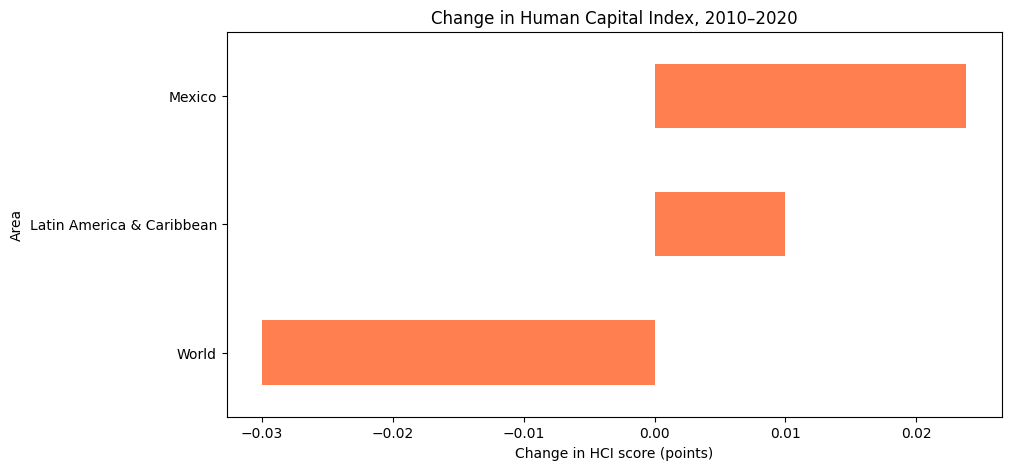

In [24]:
hci_inicio = hci[hci['TIME_PERIOD'] == 2010].set_index('REF_AREA_LABEL')
hci_final = hci[hci['TIME_PERIOD'] == 2020].set_index('REF_AREA_LABEL')
areas = ['World', 'Latin America & Caribbean', 'Mexico']
cambio = hci_final.loc[areas, 'OBS_VALUE'] - hci_inicio.loc[areas, 'OBS_VALUE']
print('Change from 2010 to 2020 (HCI points):')
print(cambio)

cambio.plot(kind='barh', figsize=(10, 5), color='coral')
plt.title('Change in Human Capital Index, 2010–2020')
plt.xlabel('Change in HCI score (points)')
plt.ylabel('Area')
plt.show()

### Insights
From 2010 to 2020, Mexico gained 0.024 HCI points and Latin America & Caribbean gained 0.010, while the World aggregate fell 0.030 based on given dataset.


##RQ3: Was Mexico’s HCI different for females and males in 2020?

[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study: Filter the same HCI indicator to Mexico and 2020, then compare the two sex categories with bars.

SEX_LABEL
Male      0.599545
Female    0.626667
Name: OBS_VALUE, dtype: float64


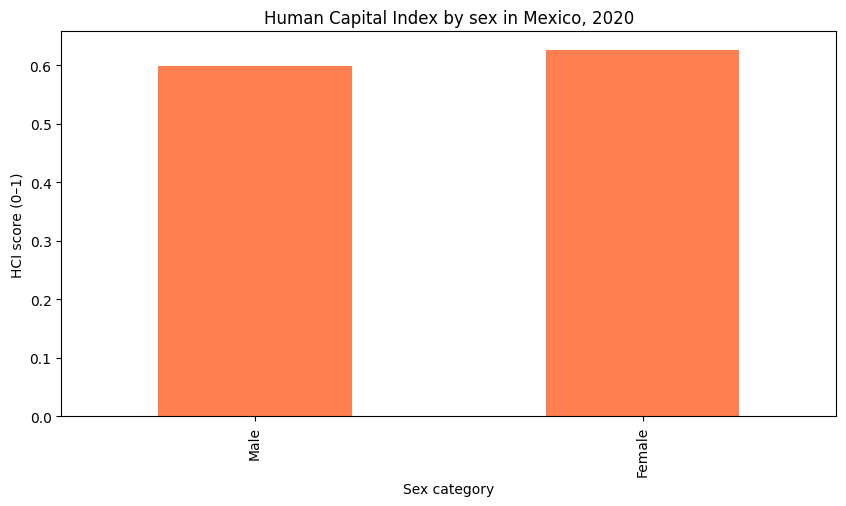

In [33]:
mexico_sexo = df[df['INDICATOR'] == 'WB_HCI_HCI']
mexico_sexo = mexico_sexo[mexico_sexo['REF_AREA_LABEL'] == 'Mexico']
mexico_sexo = mexico_sexo[mexico_sexo['TIME_PERIOD'] == 2020]
sexo_2020 = mexico_sexo.set_index('SEX_LABEL').loc[['Male', 'Female'], 'OBS_VALUE']
print(sexo_2020)

sexo_2020.plot(kind='bar', figsize=(10, 5), color='coral')
plt.title('Human Capital Index by sex in Mexico, 2020')
plt.xlabel('Sex category')
plt.ylabel('HCI score (0–1)')
plt.show()

##Insight
Mexico’s 2020 HCI was 0.613. The Latin America & Caribbean and World aggregate entries both show 0.560, so Mexico was about 0.053 index points higher in this comparison.

##RQ4: Was Mexico’s HCI different for females and males in 2020?

[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study: Use the same HCI indicator for Mexico in 2020, select Male and Female, and compare the two scores with a bar plot.

SEX_LABEL
Male      0.599545
Female    0.626667
Name: OBS_VALUE, dtype: float64


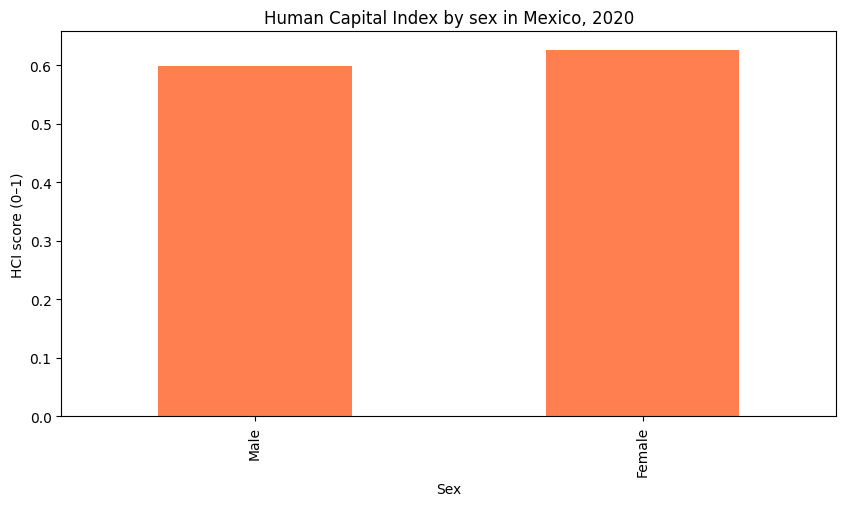

In [26]:
mexico_sexo = df[df['INDICATOR'] == 'WB_HCI_HCI']
mexico_sexo = mexico_sexo[mexico_sexo['REF_AREA_LABEL'] == 'Mexico']
mexico_sexo = mexico_sexo[mexico_sexo['TIME_PERIOD'] == 2020]
sexo_2020 = mexico_sexo.set_index('SEX_LABEL').loc[['Male', 'Female'], 'OBS_VALUE']
print(sexo_2020)

sexo_2020.plot(kind='bar', figsize=(10, 5), color='coral')
plt.title('Human Capital Index by sex in Mexico, 2020')
plt.xlabel('Sex')
plt.ylabel('HCI score (0–1)')
plt.show()

##Insight
Mexico’s female HCI was 0.627, compared with 0.600 for males in 2020: a difference of about 0.027 index points. The chart does not explain the reason for the difference.

##RQ5: How did expected and learning-adjusted years of school compare in Mexico in 2020?
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study: Compare two schooling indicators, both measured in years, using a horizontal bar plot. Learning-adjusted years take learning into account.

INDICATOR_LABEL
Expected Years of School             12.824008
Learning-Adjusted Years of School     8.824254
Name: OBS_VALUE, dtype: float64


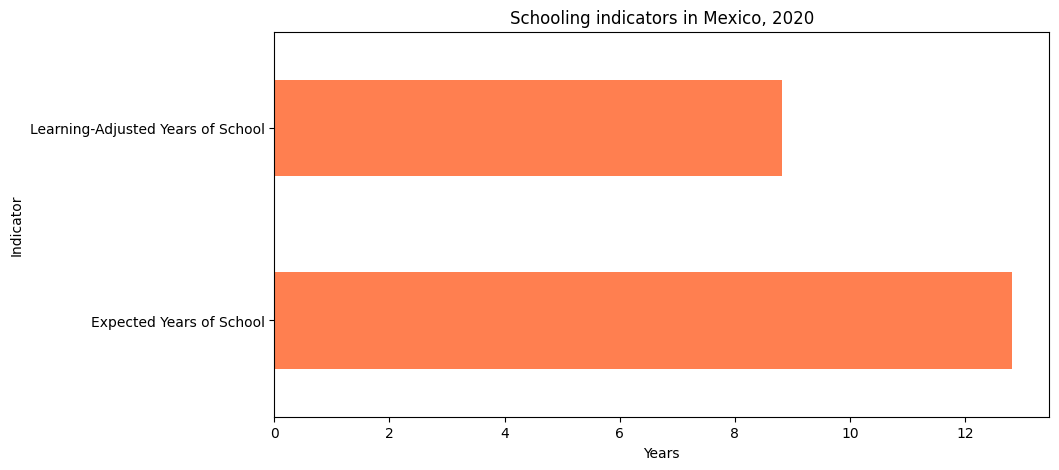

In [27]:
escuela = df[df['REF_AREA_LABEL'] == 'Mexico']
escuela = escuela[escuela['SEX_LABEL'] == 'Total']
escuela = escuela[escuela['TIME_PERIOD'] == 2020]
escuela = escuela.set_index('INDICATOR_LABEL')
indicadores = ['Expected Years of School', 'Learning-Adjusted Years of School']
anios = escuela.loc[indicadores, 'OBS_VALUE']
print(anios)

anios.plot(kind='barh', figsize=(10, 5), color='coral')
plt.title('Schooling indicators in Mexico, 2020')
plt.xlabel('Years')
plt.ylabel('Indicator')
plt.show()

##Insight
Mexico recorded 12.824 expected years of school and 8.824 learning-adjusted years in 2020, a gap of about 4.000 years between the two measures. They are different indicators, not observed years of attendance for a particular person.

##RQ6: How did learning-adjusted years of school change in Mexico?
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study: Select Mexico’s Total observations for the learning-adjusted schooling indicator, order them by year, and create an area plot.

TIME_PERIOD
2010    8.503864
2018    8.812746
2020    8.824254
Name: OBS_VALUE, dtype: float64


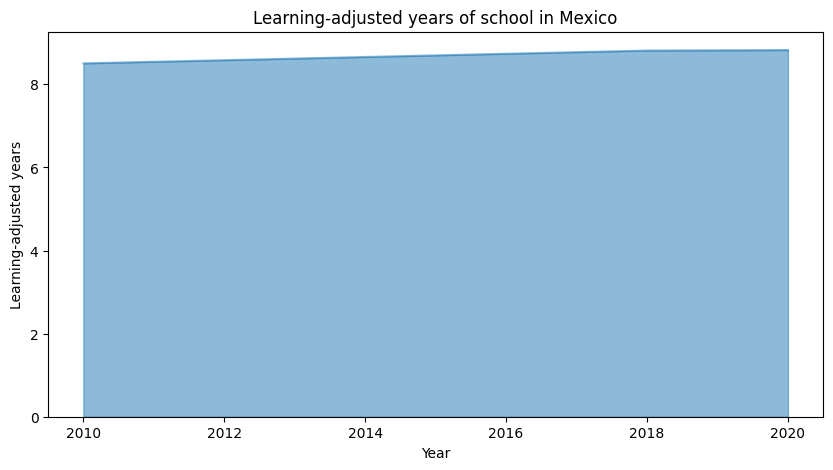

In [28]:
aprendizaje = df[df['INDICATOR'] == 'WB_HCI_LAYS']
aprendizaje = aprendizaje[aprendizaje['SEX_LABEL'] == 'Total']
aprendizaje = aprendizaje[aprendizaje['REF_AREA_LABEL'] == 'Mexico']
aprendizaje = aprendizaje.sort_values(['TIME_PERIOD']).set_index('TIME_PERIOD')['OBS_VALUE']
print(aprendizaje)

aprendizaje.plot(kind='area', stacked=False, alpha=0.5, figsize=(10, 5))
plt.title('Learning-adjusted years of school in Mexico')
plt.xlabel('Year')
plt.ylabel('Learning-adjusted years')
plt.show()

##Insight
Learning-adjusted years of school rose from 8.504 in 2010 to 8.824 in 2020, an increase of about 0.320 years. The plot connects only three observed years; there are no annual observations between them in this selection.

##RQ7: How did Mexico’s adult survival rate compare with the region and world in 2020?
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study: Select the adult survival indicator for the Total sex category in 2020 and compare the three areas with a horizontal bar plot.

REF_AREA_LABEL
World                        0.848294
Latin America & Caribbean    0.861757
Mexico                       0.861477
Name: OBS_VALUE, dtype: float64


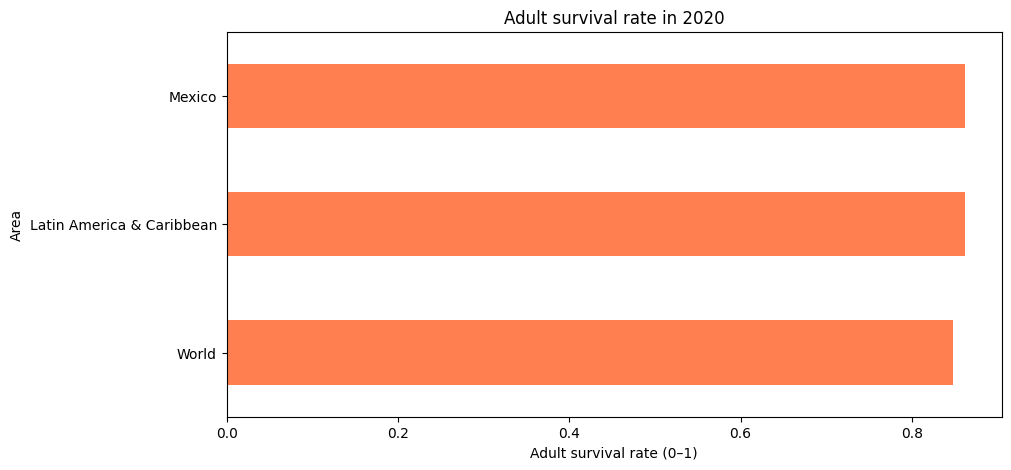

In [29]:
supervivencia = df[df['INDICATOR'] == 'WB_HCI_ASR']
supervivencia = supervivencia[supervivencia['SEX_LABEL'] == 'Total']
supervivencia = supervivencia[supervivencia['TIME_PERIOD'] == 2020].set_index('REF_AREA_LABEL')
areas = ['World', 'Latin America & Caribbean', 'Mexico']
tasas = supervivencia.loc[areas, 'OBS_VALUE']
print(tasas)

tasas.plot(kind='barh', figsize=(10, 5), color='coral')
plt.title('Adult survival rate in 2020')
plt.xlabel('Adult survival rate (0–1)')
plt.ylabel('Area')
plt.show()

##Insight
Mexico’s adult survival rate was 0.8615 in 2020, almost the same as the regional aggregate (0.8618) and higher than the World aggregate (0.8483). This is a separate health indicator; it is not the HCI score.

##RQ8: How are schooling and adult survival associated with HCI across countries in 2020?

[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Study / model: Use a two predictor linear regression to explain differences in HCI among the 174 country rows in 2020 (Total). The outcome Y is HCI (0–1); explanatory variables X₁ and X₂ are learning-adjusted years of school (LAYS, years) and adult survival rate (ASR, 0–1). Exclude 12 World, region, and income-group aggregate rows so each observation represents a country.

Equation: HCI = β₀ + β₁ × LAYS + β₂ × ASR + residual. Plot observed against fitted HCI; points nearer the dashed equal-value line have smaller residuals. Report coefficients, R², correlations, Mexico’s fitted HCI, and the countries with the largest residuals.

Number of countries: 174
Intercept β0: -0.039255560364943376
LAYS coefficient β1: 0.04911675973958726
ASR coefficient β2: 0.2555147747613098
R²: 0.9863000031974143
Correlation, HCI and LAYS: 0.9875220312580202
Correlation, HCI and ASR: 0.8017278706957782
Mexico fitted HCI: 0.6142834024427687
Mexico observed HCI: 0.6129498481750488
Largest absolute residuals:
REF_AREA_LABEL
Liberia                     0.051686
South Sudan                 0.049387
Central African Republic    0.047351
dtype: float64


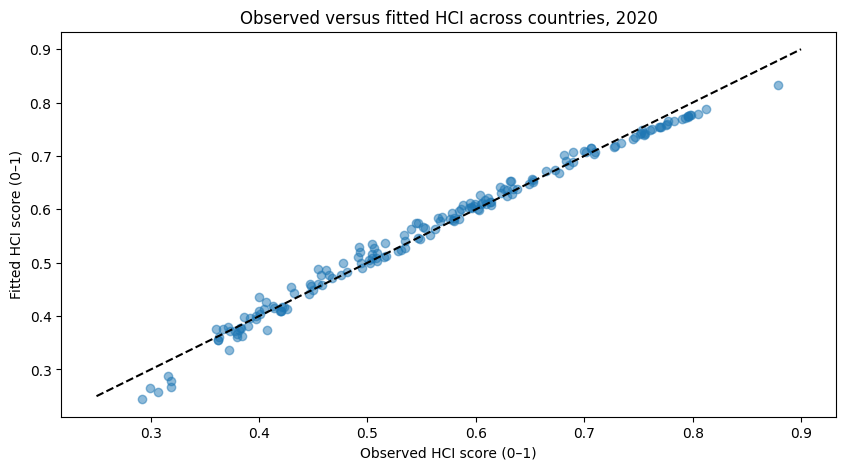

In [31]:
from sklearn import linear_model

agregados = ['WLD', 'EAS', 'ECS', 'HIC', 'LCN', 'LIC', 'LMC',
             'MEA', 'NAC', 'SAS', 'SSF', 'UMC']
datos_2020 = df[df['TIME_PERIOD'] == 2020]
datos_2020 = datos_2020[datos_2020['SEX_LABEL'] == 'Total']
datos_2020 = datos_2020[~datos_2020['REF_AREA'].isin(agregados)]

hci_pais = datos_2020[datos_2020['INDICATOR'] == 'WB_HCI_HCI'].set_index('REF_AREA_LABEL')['OBS_VALUE']
lays_pais = datos_2020[datos_2020['INDICATOR'] == 'WB_HCI_LAYS'].set_index('REF_AREA_LABEL')['OBS_VALUE']
asr_pais = datos_2020[datos_2020['INDICATOR'] == 'WB_HCI_ASR'].set_index('REF_AREA_LABEL')['OBS_VALUE']

reg = pd.DataFrame({'HCI': hci_pais, 'LAYS': lays_pais, 'ASR': asr_pais}).dropna()
x = reg[['LAYS', 'ASR']]
y = reg['HCI']

lm = linear_model.LinearRegression()
modelo = lm.fit(x, y)
ajustados = pd.Series(modelo.predict(x), index=reg.index)
residuos = y - ajustados

print('Number of countries:', len(reg))
print('Intercept β0:', modelo.intercept_)
print('LAYS coefficient β1:', modelo.coef_[0])
print('ASR coefficient β2:', modelo.coef_[1])
print('R²:', modelo.score(x, y))
print('Correlation, HCI and LAYS:', reg['HCI'].corr(reg['LAYS']))
print('Correlation, HCI and ASR:', reg['HCI'].corr(reg['ASR']))
print('Mexico fitted HCI:', ajustados.loc['Mexico'])
print('Mexico observed HCI:', y.loc['Mexico'])
print('Largest absolute residuals:')
print(residuos.abs().sort_values(ascending=False).head(3))

plt.figure(figsize=(10, 5))
plt.scatter(y, ajustados, alpha=0.5)
plt.plot([0.25, 0.9], [0.25, 0.9], color='black', linestyle='--')
plt.title('Observed versus fitted HCI across countries, 2020')
plt.xlabel('Observed HCI score (0–1)')
plt.ylabel('Fitted HCI score (0–1)')
plt.show()

##Results and insights
Estimated equation: HCI ≈ −0.0393 + 0.0491 × LAYS + 0.2555 × ASR. Holding ASR fixed, one more LAYS year is associated with approximately 0.0491 HCI points. Holding LAYS fixed, a 0.01 higher ASR is associated with approximately 0.0026 HCI points. The intercept describes a hypothetical zero/zero case outside the observed data and has no practical country interpretation.

Model fit and example: R² ≈ 0.986. The correlations of HCI with LAYS and ASR are 0.988 and 0.802. The fitted value for Mexico is 0.614, close to its observed 0.613. Liberia, South Sudan, and Central African Republic have the largest absolute residuals (about 0.047–0.052), so their model fit merits closer inspection.

Limit: HCI is itself based partly on education and health. A high in-sample R² is therefore unsurprising; this model does not prove causation or demonstrate future prediction accuracy. Mexico’s estimate is an in-sample fitted value, not a forecast.

##Final conclusions
[Initial setup](#scrollTo=vseoY8IkIjKN&line)

Across the eight studies, Mexico’s HCI increased 0.024 points from 2010 to 2020. In 2020 it exceeded the World and regional aggregate entries and ranked second among the four countries selected for RQ7. Mexico’s female score was 0.027 points higher than its male score. These are descriptive comparisons; they do not reveal what caused the differences.

The education studies show a 4.000-year gap between expected and learning-adjusted years of school in 2020, although the learning-adjusted measure increased 0.320 years since 2010. Adult survival was close to the regional entry. Across 174 countries, schooling and adult survival were strongly associated with HCI (R² ≈ 0.986); Mexico’s in-sample fitted score (0.614) was close to its observed score (0.613). A practical next step is to investigate the learning-adjusted schooling gap rather than treating the regression as proof of a policy effect.

Limitations: The trend graphs contain only three observed years. Regional/World entries are aggregates, whereas the regression uses only country rows. HCI includes health and education information, so the regression’s strong fit should not be interpreted as causal or as validated forecasting performance.